# 📌 Recommender System for E-Commerce (Green Store)

---

## 1. Introduction

### 🔍 Problem Statement

In modern e-commerce platforms, users are often overwhelmed by the vast number of available products, making it difficult to discover relevant items efficiently. This leads to poor user experience and reduced conversion rates.

The goal of this project is to design and implement a **personalized recommendation system** for an online retail platform (“Green Store”) using collaborative filtering techniques. The system leverages historical user-item interaction data to identify patterns in user preferences and recommend products that align with individual tastes.

### 🎯 Objectives

* Build a recommendation system using collaborative filtering
* Analyze user-item interaction patterns
* Generate personalized product recommendations
* Evaluate and improve recommendation quality

---

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

---

## 3. Load Dataset

In [2]:
ratings_df = pd.read_csv('https://raw.githubusercontent.com/BuhariS/ratings/refs/heads/main/product_ratings.csv', index_col=0)


In [3]:
ratings_df = pd.read_csv('https://raw.githubusercontent.com/BuhariS/ratings/refs/heads/main/product_ratings.csv', index_col=0)
ratings_df.head()

,user_id,item_id,rating
0,user_51,Wireless Mouse,4
1,user_92,Sportswear,5
2,user_14,Wristwatch,5
3,user_71,Router,2
4,user_60,External Hard Drive,5


### Dataset Description

* user_id: Unique identifier for users
* item_id: Unique identifier for products
* rating: User rating for a product

---

## 4. Exploratory Data Analysis (EDA)

### 📊 Basic Info

In [4]:
ratings_df.info()
ratings_df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 1637 entries, 0 to 1998
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  1637 non-null   object
 1   item_id  1637 non-null   object
 2   rating   1637 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 51.2+ KB


,rating
count,1637.000000
mean,3.006109
std,1.411605
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,5.000000


### 📊 Ratings Distribution

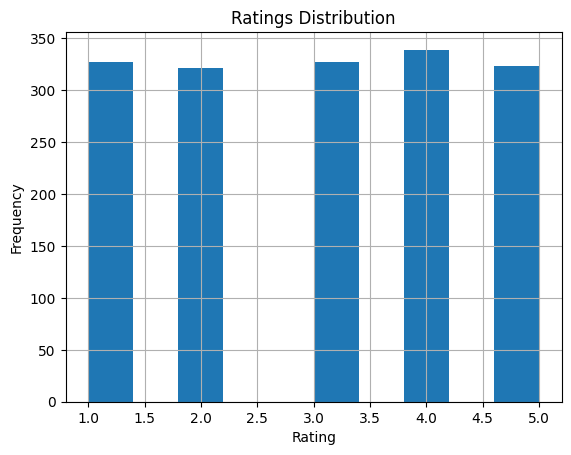

In [5]:
ratings_df['rating'].hist()
plt.title("Ratings Distribution")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

### 📊 Top Products

In [6]:
ratings_df['item_id'].value_counts().head(10)

item_id
Webcam            50
Tablet            44
Shoes             43
Agbada            41
Wireless Mouse    37
Headphones        37
Sneakers          37
Samsung Galaxy    36
Scarf             36
Microphone        36
Name: count, dtype: int64

### 📊 Most Active Users

In [7]:
ratings_df['user_id'].value_counts().head(10)

user_id
user_61    25
user_91    24
user_32    23
user_98    23
user_89    22
user_97    21
user_39    21
user_88    21
user_86    20
user_58    20
Name: count, dtype: int64

### 💡 Insights

* Some products are rated much more frequently (popularity bias)
* Most users interact with a limited number of items
* Data is sparse, which is common in recommendation systems

---

## 5. Data Preparation

### 🔄 Create User-Item Matrix

In [8]:
user_item_matrix = ratings_df.pivot_table(
    index='user_id',
    columns='item_id',
    values='rating'
)

user_item_matrix.fillna(0, inplace=True)
user_item_matrix.head()

item_id,Agbada,Ankara Dress,Belt,Blazer,Bluetooth Speaker,Boots,Camera,Cap,Dress,Drone,...,Sunglasses,T-Shirt,Tablet,Tracksuit,VR Headset,Wallet,Webcam,Wireless Mouse,Wristwatch,iPhone
user_id,,,,,,,,,,,,,,,,,,,,,
user_0,3.0,0.0,0.0,1.0,0.0,0.0,2.0,5.0,0.0,0.0,...,0.0,3.0,0.0,5.0,0.0,4.0,2.0,0.0,0.0,0.0
user_1,1.0,3.0,0.0,0.0,5.0,0.0,2.0,0.0,0.0,0.0,...,2.0,0.0,2.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0
user_10,3.0,0.0,5.0,2.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,3.0,0.0,0.0,0.0,1.0,0.0,1.0,2.0,0.0
user_11,4.0,0.0,0.0,5.0,2.0,0.0,3.0,2.0,0.0,3.0,...,0.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0
user_12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,2.0,...,0.0,4.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,3.0


### 💡 Explanation

* Rows represent users
* Columns represent items
* Missing values are filled with 0 (no interaction)

---

## 6. Similarity Calculation

### 📐 Cosine Similarity

In [9]:
user_similarity = cosine_similarity(user_item_matrix)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

user_similarity_df.head()

user_id,user_0,user_1,user_10,user_11,user_12,user_13,user_14,user_15,user_16,user_17,...,user_90,user_91,user_92,user_93,user_94,user_95,user_96,user_97,user_98,user_99
user_id,,,,,,,,,,,,,,,,,,,,,
user_0,1.000000,0.219554,0.404285,0.398326,0.378225,0.375567,0.249446,0.283436,0.443987,0.171382,...,0.370993,0.306488,0.357696,0.345857,0.313932,0.431976,0.253933,0.319897,0.308495,0.080197
user_1,0.219554,1.000000,0.265422,0.157393,0.289259,0.296665,0.292755,0.448278,0.298507,0.325413,...,0.225528,0.340940,0.249562,0.272734,0.260435,0.316248,0.101544,0.500175,0.295510,0.293435
user_10,0.404285,0.265422,1.000000,0.270868,0.401303,0.342869,0.337756,0.214249,0.638143,0.157328,...,0.198191,0.294859,0.207011,0.309581,0.357209,0.256410,0.253578,0.306092,0.286742,0.278477
user_11,0.398326,0.157393,0.270868,1.000000,0.332678,0.258715,0.205704,0.192621,0.284323,0.104547,...,0.118789,0.327224,0.264477,0.187152,0.370982,0.288157,0.259067,0.337332,0.321028,0.279819
user_12,0.378225,0.289259,0.401303,0.332678,1.000000,0.428099,0.407479,0.348382,0.376496,0.244701,...,0.315557,0.393305,0.473915,0.286416,0.270392,0.192834,0.196795,0.345195,0.409077,0.332955


### 💡 Why Cosine Similarity?

* Measures similarity between users based on rating patterns
* Works well for sparse data

---

## 7. Recommendation Function

In [10]:
def recommend_items(user_id, user_item_matrix, user_similarity_df, top_n=5):

    # Get similar users
    similar_users = user_similarity_df[user_id].sort_values(ascending=False)[1:]

    # Get items the user has already interacted with
    user_items = user_item_matrix.loc[user_id]
    already_rated = user_items[user_items > 0].index

    # Weighted recommendation scores
    recommendation_scores = pd.Series(dtype=float)

    for other_user, similarity_score in similar_users.items():
        other_user_ratings = user_item_matrix.loc[other_user]
        recommendation_scores = recommendation_scores.add(
            other_user_ratings * similarity_score,
            fill_value=0
        )

    # Remove already rated items
    recommendation_scores = recommendation_scores.drop(already_rated, errors='ignore')

    # Return top N recommendations
    return recommendation_scores.sort_values(ascending=False).head(top_n)

### ▶ Example Usage

In [11]:
recommend_items(user_id='user_1', user_item_matrix=user_item_matrix, user_similarity_df=user_similarity_df)

item_id
Webcam            42.046570
Samsung Galaxy    33.506763
Tracksuit         33.412673
T-Shirt           32.148574
Wristwatch        31.345822
dtype: float64

---

## 7.5. Item-Based Collaborative Filtering

### 📐 Item Similarity Calculation

In [12]:
item_similarity = cosine_similarity(user_item_matrix.T)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=user_item_matrix.columns,
    columns=user_item_matrix.columns
)

item_similarity_df.head()

item_id,Agbada,Ankara Dress,Belt,Blazer,Bluetooth Speaker,Boots,Camera,Cap,Dress,Drone,...,Sunglasses,T-Shirt,Tablet,Tracksuit,VR Headset,Wallet,Webcam,Wireless Mouse,Wristwatch,iPhone
item_id,,,,,,,,,,,,,,,,,,,,,
Agbada,1.000000,0.460934,0.226776,0.306578,0.323387,0.238559,0.310802,0.346422,0.206990,0.197409,...,0.372792,0.334335,0.360286,0.501325,0.302081,0.231087,0.376298,0.327449,0.274657,0.330227
Ankara Dress,0.460934,1.000000,0.193825,0.233139,0.418692,0.250734,0.247208,0.132790,0.322846,0.286384,...,0.394505,0.239636,0.382631,0.286885,0.257499,0.294212,0.378636,0.300680,0.208822,0.233884
Belt,0.226776,0.193825,1.000000,0.242033,0.231445,0.155994,0.130615,0.335415,0.165859,0.175683,...,0.189967,0.183415,0.223187,0.334789,0.285128,0.053046,0.385238,0.119609,0.255876,0.188137
Blazer,0.306578,0.233139,0.242033,1.000000,0.259790,0.288539,0.226250,0.388634,0.219223,0.145371,...,0.246312,0.326092,0.327154,0.247355,0.255313,0.230440,0.323037,0.146209,0.154826,0.225060
Bluetooth Speaker,0.323387,0.418692,0.231445,0.259790,1.000000,0.300420,0.274983,0.226451,0.226559,0.372309,...,0.282872,0.253153,0.310839,0.356278,0.416190,0.267990,0.474550,0.337009,0.228573,0.299211


### 💡 Explanation

*   Here, we transpose the `user_item_matrix` to calculate similarity between items (columns).
*   `cosine_similarity` is again used to find how similar items are based on how users have rated them.

### 📦 Item-Based Recommendation Function

In [13]:
def recommend_items_item_based(user_id, user_item_matrix, item_similarity_df, top_n=5):
    user_ratings = user_item_matrix.loc[user_id]

    # Get items the user has not rated yet
    unrated_items = user_ratings[user_ratings == 0].index
    rated_items = user_ratings[user_ratings > 0].index

    # Calculate a score for each unrated item
    recommendation_scores = pd.Series(0.0, index=unrated_items)

    for item_to_recommend in unrated_items:
        for rated_item in rated_items:
            if rated_item in item_similarity_df.index and item_to_recommend in item_similarity_df.columns:
                similarity = item_similarity_df.loc[rated_item, item_to_recommend]
                rating = user_ratings[rated_item]
                recommendation_scores[item_to_recommend] += similarity * rating

    return recommendation_scores.sort_values(ascending=False).head(top_n)

### ▶ Example Usage (Item-Based)

In [14]:
recommend_items_item_based(user_id='user_1', user_item_matrix=user_item_matrix, item_similarity_df=item_similarity_df)

item_id
Webcam            18.438032
Tracksuit         17.288904
Samsung Galaxy    16.967333
T-Shirt           15.873215
Wristwatch        15.727936
dtype: float64

---

🔥 1. Add Item-Based Collaborative Filtering
Right now you only have:

User → User similarity

Item → Item similarity (more scalable & commonly used)

In [15]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(ratings_df, test_size=0.2, random_state=42)

train_matrix = train.pivot_table(index='user_id', columns='item_id', values='rating').fillna(0)
test_matrix = test.pivot_table(index='user_id', columns='item_id', values='rating').fillna(0)

In [16]:
def precision_at_k(actual, predicted, k=5):
    predicted = predicted[:k]
    return len(set(predicted) & set(actual)) / k

## 8. Basic Evaluation

### ⚠️ Note

Evaluating recommender systems can be complex. Here we perform a simple validation.

### ✔ Approach

* Hide some user interactions
* Check if recommended items match actual preferences

In [17]:
# Example: checking overlap manually
user_id = 'user_1'
recommended = recommend_items(user_id, user_item_matrix, user_similarity_df)
print(recommended)

item_id
Webcam            42.046570
Samsung Galaxy    33.506763
Tracksuit         33.412673
T-Shirt           32.148574
Wristwatch        31.345822
dtype: float64


### 💡 Future Evaluation Metrics

* Precision@K
* Recall@K
* Mean Average Precision (MAP)

---

⭐ Matrix Factorization (SVD)

In [18]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=20)
matrix_svd = svd.fit_transform(user_item_matrix)

reconstructed_matrix = np.dot(matrix_svd, svd.components_)

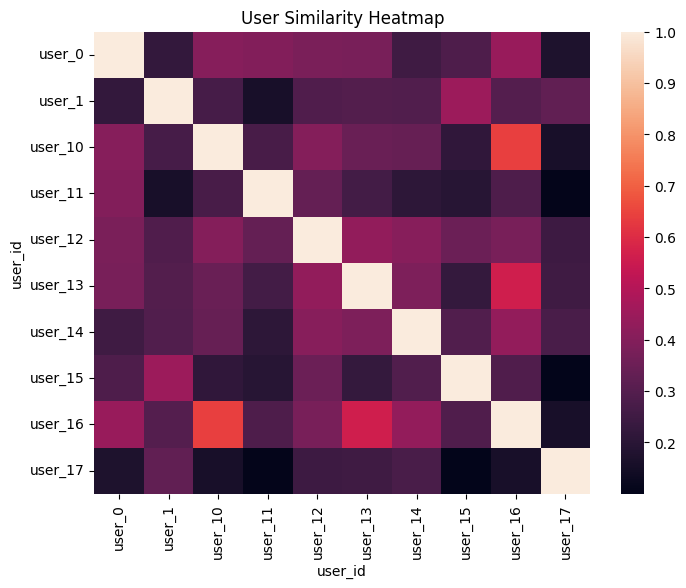

In [19]:
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(user_similarity_df.iloc[:10, :10], annot=False)
plt.title("User Similarity Heatmap")
plt.show()

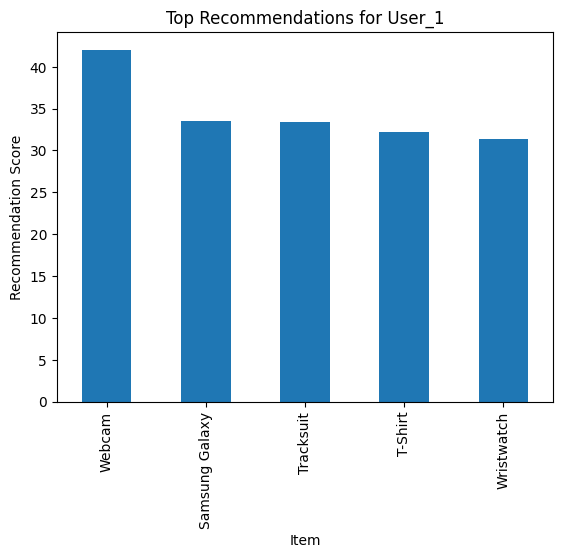

In [20]:
recommendations = recommend_items(user_id='user_1', user_item_matrix=user_item_matrix, user_similarity_df=user_similarity_df)

recommendations.plot(kind='bar')
plt.title("Top Recommendations for User_1")
plt.xlabel("Item")
plt.ylabel("Recommendation Score")
plt.show()

Generate Top Recommendations

In [21]:
user_to_recommend = 'user_1'
recommended_items = recommend_items(
    user_id=user_to_recommend,
    user_item_matrix=user_item_matrix,
    user_similarity_df=user_similarity_df
)

print(f"Top recommendations for {user_to_recommend}:\n")
print(recommended_items)

Top recommendations for user_1:

item_id
Webcam            42.046570
Samsung Galaxy    33.506763
Tracksuit         33.412673
T-Shirt           32.148574
Wristwatch        31.345822
dtype: float64


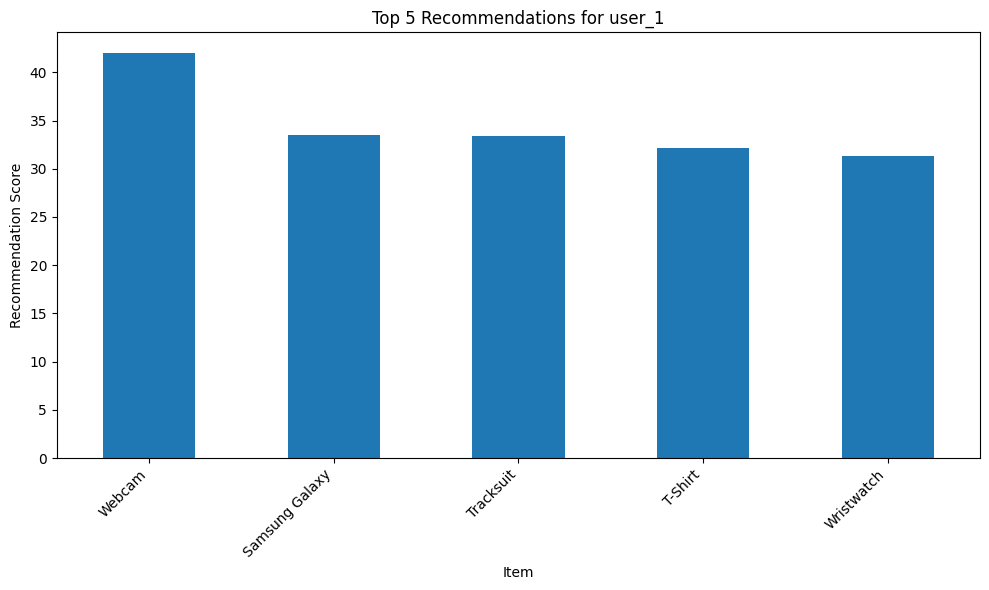

In [22]:
recommended_items.plot(kind='bar', figsize=(10, 6))
plt.title(f"Top 5 Recommendations for {user_to_recommend}")
plt.xlabel("Item")
plt.ylabel("Recommendation Score")
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

## 9. Challenges

### ⚠️ Cold Start Problem

* New users or items have no data

### ⚠️ Data Sparsity

* Most users rate very few items

### ⚠️ Scalability

* Large datasets require optimized computation

---

## 10. Improvements

### 🚀 Possible Enhancements

* Item-based collaborative filtering
* Matrix Factorization (SVD)
* Deep learning models
* Hybrid recommendation systems

---

## 11. Conclusion

This project demonstrates how collaborative filtering can be used to build a personalized recommendation system. By leveraging user similarity, the model can suggest relevant items to users based on collective behavior.

While effective for smaller datasets, further improvements such as advanced modeling techniques and scalability optimizations are required for production-level deployment.

---

## 12. Future Work

* Deploy as an API using Flask/Django
* Integrate with frontend applications
* Real-time recommendation updates

---